# **1. Perkenalan Dataset**

**Sumber data:** Investing.com

**Instrumen yang digunakan:**
- `XAU_USD Historical Data.csv`: harga emas terhadap USD.
- `CHF_USD Historical Data.csv`: nilai Swiss Franc terhadap USD.

**Periode pengamatan:** 1 Januari 2010 - 31 Desember 2025 

**Tujuan penggunaan dataset:** Menyiapkan dataset untuk memprediksi *return* harga emas sebagai variabel target berdasarkan *return* Swiss Franc serta *return* emas pada periode-periode sebelumnya. Dataset akhir digunakan untuk pemodelan dengan model-model regresi berbasis *decision tree*.

**Variabel target:** `return_gold`.

**Variabel prediktor:**
- `return_gold_lag_1`, `return_gold_lag_2`, `return_gold_lag_3` (return emas periode sebelumnya).
- `return_chf_lag_1`, `return_chf_lag_2`, `return_chf_lag_3` (return Swiss Franc periode sebelumnya).

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True

print('pandas :', pd.__version__)
print('numpy  :', np.__version__)

pandas : 3.0.6
numpy  : 2.4.6


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

Dataset dimuat langsung dari folder `dataset_harga_emas_dan_swiss_franc_raw`. Path relatif diarahkan dari folder `preprocessing` (lokasi notebook) menggunakan `../`, dan dataset hasil preprocessing disimpan pada folder yang sama. Jalankan notebook dari dalam folder `preprocessing`.

In [2]:
GOLD_PATH = Path('../dataset_harga_emas_dan_swiss_franc_raw/XAU_USD Historical Data.csv')
CHF_PATH = Path('../dataset_harga_emas_dan_swiss_franc_raw/CHF_USD Historical Data.csv')
OUTPUT_PATH = Path('harga_emas_dan_swiss_franc_preprocessing.csv')

In [3]:
gold_raw = pd.read_csv(GOLD_PATH)
chf_raw = pd.read_csv(CHF_PATH)

print('Tabel XAU/USD')
display(gold_raw.head())
print('\nTabel CHF/USD')
display(chf_raw.head())

Tabel XAU/USD


,Date,Price,Open,High,Low,Vol.,Change %
0,12/31/2025,"4,315.09","4,346.47","4,373.89","4,274.51",NaN,-0.72%
1,12/30/2025,"4,346.51","4,332.09","4,404.51","4,323.33",NaN,0.33%
2,12/29/2025,"4,332.08","4,540.70","4,550.10","4,303.75",NaN,-4.42%
3,12/26/2025,"4,532.63","4,479.64","4,550.11","4,475.10",NaN,0.83%
4,12/25/2025,"4,495.35","4,487.10","4,500.35","4,483.59",NaN,0.35%



Tabel CHF/USD


,Date,Price,Open,High,Low,Vol.,Change %
0,12/31/2025,1.2616,1.2632,1.2634,1.2588,NaN,-0.13%
1,12/30/2025,1.2632,1.2680,1.2698,1.2618,NaN,-0.33%
2,12/29/2025,1.2674,1.2678,1.2703,1.2631,NaN,0.06%
3,12/26/2025,1.2667,1.2694,1.2707,1.2650,NaN,-0.25%
4,12/25/2025,1.2699,1.2685,1.2708,1.2677,NaN,0.14%


In [4]:
summary = pd.DataFrame({
    'dataset': ['XAU_USD', 'CHF_USD'],
    'baris': [gold_raw.shape[0], chf_raw.shape[0]],
    'kolom': [gold_raw.shape[1], chf_raw.shape[1]],
    'missing_total': [int(gold_raw.isna().sum().sum()), int(chf_raw.isna().sum().sum())],
    'duplikat_baris': [int(gold_raw.duplicated().sum()), int(chf_raw.duplicated().sum())],
})
display(summary)

print('=== Tipe data XAU/USD ===')
print(gold_raw.dtypes)
print('\n=== Tipe data CHF/USD ===')
print(chf_raw.dtypes)
print('\n=== Missing values kolom mentah ===')
missing = pd.concat(
    {'XAU_USD': gold_raw.isna().sum(), 'CHF_USD': chf_raw.isna().sum()}, axis=1
)
display(missing)

,dataset,baris,kolom,missing_total,duplikat_baris
0,XAU_USD,4164,7,4164,0
1,CHF_USD,4174,7,3112,0


=== Tipe data XAU/USD ===
Date            str
Price           str
Open            str
High            str
Low             str
Vol.        float64
Change %        str
dtype: object

=== Tipe data CHF/USD ===
Date            str
Price       float64
Open        float64
High        float64
Low         float64
Vol.            str
Change %        str
dtype: object

=== Missing values kolom mentah ===


,XAU_USD,CHF_USD
Date,0,0
Price,0,0
Open,0,0
High,0,0
Low,0,0
Vol.,4164,3112
Change %,0,0


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

Pada bagian ini kita memahami karakteristik kedua dataset emas dan chf mentah sebelum melakukan preprocessing.

### 4.1 Pemilihan kolom yang dianalisis
Hanya kolom `Date` dan `Price` yang digunakan penelitian ini.

In [5]:
gold_eda = gold_raw[['Date', 'Price']].copy()
chf_eda = chf_raw[['Date', 'Price']].copy()
display(gold_eda.head())
display(gold_eda.tail())

,Date,Price
0,12/31/2025,"4,315.09"
1,12/30/2025,"4,346.51"
2,12/29/2025,"4,332.08"
3,12/26/2025,"4,532.63"
4,12/25/2025,"4,495.35"


,Date,Price
4159,01/07/2010,"1,132.30"
4160,01/06/2010,"1,138.90"
4161,01/05/2010,"1,119.05"
4162,01/04/2010,"1,120.40"
4163,01/01/2010,"1,097.35"


### 4.2 Dimensi, tipe data, dan missing values pada kolom yang digunakan

In [6]:
for name, df in [('XAU_USD', gold_eda), ('CHF_USD', chf_eda)]:
    print(f'--- {name} ---')
    print('dimensi    :', df.shape)
    print('tipe data  :')
    print(df.dtypes.to_string())
    print('missing    :', df.isna().sum().to_dict())
    print()

--- XAU_USD ---
dimensi    : (4164, 2)
tipe data  :
Date     str
Price    str
missing    : {'Date': 0, 'Price': 0}

--- CHF_USD ---
dimensi    : (4174, 2)
tipe data  :
Date         str
Price    float64
missing    : {'Date': 0, 'Price': 0}



### 4.3 Pemeriksaan duplikasi tanggal, rentang tanggal, dan urutan kronologis

In [7]:
for name, df in [('XAU_USD', gold_eda), ('CHF_USD', chf_eda)]:
    d = pd.to_datetime(df['Date'], format='%m/%d/%Y')
    print(f'--- {name} ---')
    print('duplikasi tanggal :', int(d.duplicated().sum()))
    print('tanggal minimum   :', d.min().date())
    print('tanggal maksimum  :', d.max().date())
    print('terurut menaik    :', d.is_monotonic_increasing, '(underscore: urutan file asli)')
    print('jumlah weekend    :', int((d.dt.dayofweek >= 5).sum()))
    print()

--- XAU_USD ---
duplikasi tanggal : 0
tanggal minimum   : 2010-01-01
tanggal maksimum  : 2025-12-31
terurut menaik    : False (underscore: urutan file asli)
jumlah weekend    : 0

--- CHF_USD ---
duplikasi tanggal : 0
tanggal minimum   : 2010-01-01
tanggal maksimum  : 2025-12-31
terurut menaik    : False (underscore: urutan file asli)
jumlah weekend    : 0



### 4.4 Statistik deskriptif harga

In [8]:
gold_eda['Price_num'] = pd.to_numeric(
    gold_eda['Price'].astype(str).str.replace(',', '', regex=False), errors='coerce'
)
chf_eda['Price_num'] = pd.to_numeric(chf_eda['Price'], errors='coerce')

print('=== Statistik harga emas ===')
display(gold_eda['Price_num'].describe())
print('=== Statistik CHF/USD ===')
display(chf_eda['Price_num'].describe())

=== Statistik harga emas ===


count    4164.000000
mean     1663.527068
std       584.614012
min      1051.740000
25%      1268.635000
50%      1507.000000
75%      1829.430000
max      4532.630000
Name: Price_num, dtype: float64

=== Statistik CHF/USD ===


count    4174.000000
mean        1.068723
std         0.068678
min         0.859500
25%         1.020050
50%         1.064250
75%         1.105800
max         1.383500
Name: Price_num, dtype: float64

### 4.5 Visualisasi perkembangan harga terhadap waktu

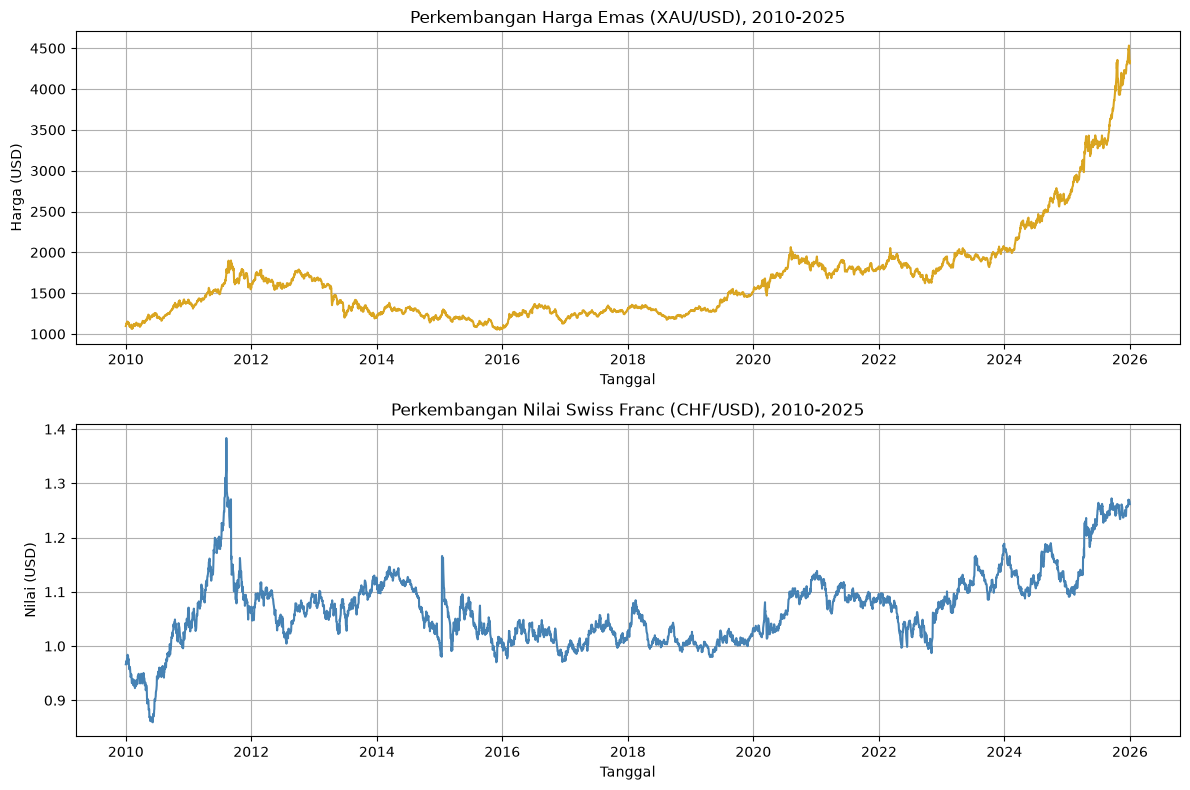

Interpretasi: harga emas menunjukkan tren naik jangka panjang dengan lonjakan
tajam pada 2020 dan 2025, sedangkan CHF/USD relatif lebih stabil di kisaran ~0.9-1.3.


In [9]:
gold_plot = gold_eda.assign(Date=pd.to_datetime(gold_eda['Date'], format='%m/%d/%Y')).sort_values('Date')
chf_plot = chf_eda.assign(Date=pd.to_datetime(chf_eda['Date'], format='%m/%d/%Y')).sort_values('Date')

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(gold_plot['Date'], gold_plot['Price_num'], color='goldenrod')
axes[0].set_title('Perkembangan Harga Emas (XAU/USD), 2010-2025')
axes[0].set_xlabel('Tanggal')
axes[0].set_ylabel('Harga (USD)')

axes[1].plot(chf_plot['Date'], chf_plot['Price_num'], color='steelblue')
axes[1].set_title('Perkembangan Nilai Swiss Franc (CHF/USD), 2010-2025')
axes[1].set_xlabel('Tanggal')
axes[1].set_ylabel('Nilai (USD)')

plt.tight_layout()
plt.show()

print('Interpretasi: harga emas menunjukkan tren naik jangka panjang dengan lonjakan')
print('tajam pada 2020 dan 2025, sedangkan CHF/USD relatif lebih stabil di kisaran ~0.9-1.3.')

### 4.6 Distribusi harga

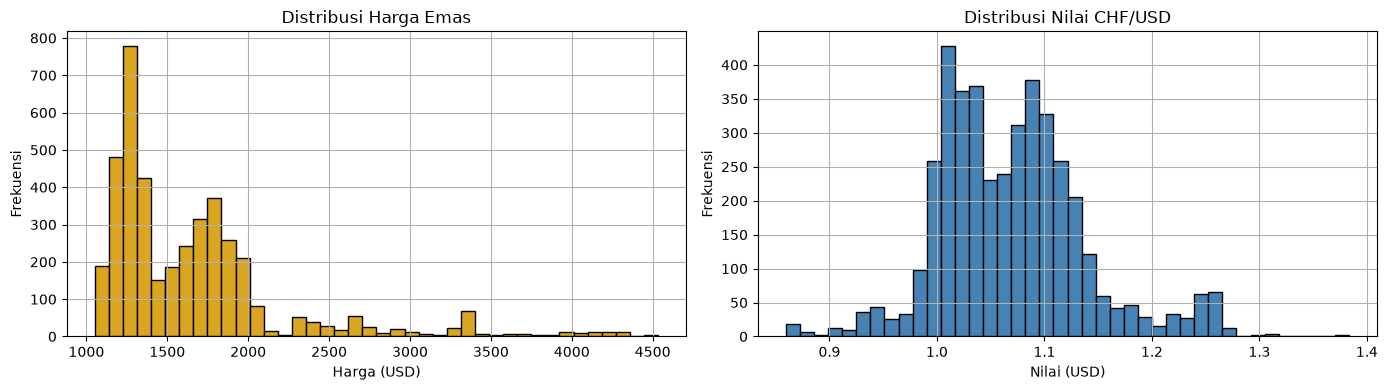

Interpretasi: distribusi harga emas miring ke kiri (left-skewed) akibat tren naik,
sedangkan CHF/USD cenderung terkonsentrasi pada kisaran nilai tertentu.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(gold_plot['Price_num'], bins=40, color='goldenrod', edgecolor='black')
axes[0].set_title('Distribusi Harga Emas')
axes[0].set_xlabel('Harga (USD)')
axes[0].set_ylabel('Frekuensi')

axes[1].hist(chf_plot['Price_num'], bins=40, color='steelblue', edgecolor='black')
axes[1].set_title('Distribusi Nilai CHF/USD')
axes[1].set_xlabel('Nilai (USD)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

print('Interpretasi: distribusi harga emas miring ke kiri (left-skewed) akibat tren naik,')
print('sedangkan CHF/USD cenderung terkonsentrasi pada kisaran nilai tertentu.')

### 4.7 Pemeriksaan kecocokan tanggal antar kedua dataset (setelah penggabungan)

In [11]:
gold_dates = set(pd.to_datetime(gold_eda['Date'], format='%m/%d/%Y'))
chf_dates = set(pd.to_datetime(chf_eda['Date'], format='%m/%d/%Y'))

print('Jumlah tanggal emas unik       :', len(gold_dates))
print('Jumlah tanggal CHF unik        :', len(chf_dates))
print('Tanggal yang sama (irisan)     :', len(gold_dates & chf_dates))
print('Tanggal hanya di emas          :', len(gold_dates - chf_dates))
print('Tanggal hanya di CHF           :', len(chf_dates - gold_dates))
print()
print('Konsekuensi: inner join akan menghasilkan', len(gold_dates & chf_dates), 'tanggal.')
print('Tanggal yang hanya ada pada salah satu dataset akan dihapus oleh inner join.')

Jumlah tanggal emas unik       : 4164
Jumlah tanggal CHF unik        : 4174
Tanggal yang sama (irisan)     : 4164
Tanggal hanya di emas          : 0
Tanggal hanya di CHF           : 10

Konsekuensi: inner join akan menghasilkan 4164 tanggal.
Tanggal yang hanya ada pada salah satu dataset akan dihapus oleh inner join.


# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

Langkah-langkah preprocessing rancangan ini sebagai berikut:
1. Memilih kolom Date dan Price dari tiap dataset mentah.
2. Konversi tipe data (datetime dan numerik).
3. Validasi, pengurutan, dan pembatasan periode 2010-01-01 s.d. 2025-12-31.
4. Penanganan missing values pada kolom yang digunakan.
5. Penghapusan tanggal weekend (Sabtu/Minggu).
6. Inner join kedua dataset berdasarkan tanggal.
7. Perhitungan simple return emas dan Swiss Franc.
8. Pembuatan fitur lag 1-3 untuk return emas dan return Swiss Franc.
9. Penghapusan baris dengan return/lag yang tidak lengkap.
10. Penyusunan dataset final delapan kolom (Date + return + lag) dan penyimpanan ke CSV.

Catatan: normalisasi/standardisasi tidak dilakukan karena model yang digunakan
berbasis decision tree.

## Tahap 1: Pemilihan kolom untuk di analisis
Hanya `Date` dan `Price` yang dipertahankan.

In [12]:
gold = gold_raw[['Date', 'Price']].rename(columns={'Price': 'gold_price'}).copy()
chf = chf_raw[['Date', 'Price']].rename(columns={'Price': 'chf_price'}).copy()

print('Kolom emas :', list(gold.columns))
print('Kolom CHF  :', list(chf.columns))
display(gold.head())

Kolom emas : ['Date', 'gold_price']
Kolom CHF  : ['Date', 'chf_price']


,Date,gold_price
0,12/31/2025,"4,315.09"
1,12/30/2025,"4,346.51"
2,12/29/2025,"4,332.08"
3,12/26/2025,"4,532.63"
4,12/25/2025,"4,495.35"


## Tahap 2: Konversi tipe data, validasi, pengurutan, dan pembatasan periode

In [13]:
START_DATE, END_DATE = '2010-01-01', '2025-12-31'

def convert_types(df, price_col, label):
    df = df.copy()
    raw_n = len(df)

    df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='coerce')
    invalid_date = int(df['Date'].isna().sum())

    df[price_col] = pd.to_numeric(
        df[price_col].astype(str).str.replace(',', '', regex=False).str.strip(),
        errors='coerce',
    )
    invalid_price = int(df[price_col].isna().sum())

    print(f'--- {label} ({raw_n} baris) ---')
    print(f'  tanggal gagal dikonversi : {invalid_date}')
    print(f'  harga gagal dikonversi   : {invalid_price}')
    return df, raw_n, invalid_date, invalid_price

gold, gold_n, gold_bad_date, gold_bad_price = convert_types(gold, 'gold_price', 'Emas')
chf, chf_n, chf_bad_date, chf_bad_price = convert_types(chf, 'chf_price', 'CHF')

--- Emas (4164 baris) ---
  tanggal gagal dikonversi : 0
  harga gagal dikonversi   : 0
--- CHF (4174 baris) ---
  tanggal gagal dikonversi : 0
  harga gagal dikonversi   : 0


In [14]:
def validate_sort_filter(df, price_col, label):
    n0 = len(df)
    df = df.dropna(subset=['Date', price_col]).copy()
    n1 = len(df)

    df = df.sort_values('Date').reset_index(drop=True)

    mask = (df['Date'] >= START_DATE) & (df['Date'] <= END_DATE)
    outside = int((~mask).sum())
    df = df.loc[mask].reset_index(drop=True)

    dupes = int(df['Date'].duplicated().sum())
    if dupes:
        df = df.drop_duplicates(subset='Date', keep='first').reset_index(drop=True)

    print(f'--- {label} ---')
    print(f'  {n0} -> dropna -> {n1} (hapus {n0 - n1})')
    print(f'  di luar periode {START_DATE}..{END_DATE} : {outside}')
    print(f'  duplikasi tanggal dihapus : {dupes}')
    print(f'  baris bersih : {len(df)}; urut menaik : {df["Date"].is_monotonic_increasing}')
    return df

gold = validate_sort_filter(gold, 'gold_price', 'Emas')
chf = validate_sort_filter(chf, 'chf_price', 'CHF')

--- Emas ---
  4164 -> dropna -> 4164 (hapus 0)
  di luar periode 2010-01-01..2025-12-31 : 0
  duplikasi tanggal dihapus : 0
  baris bersih : 4164; urut menaik : True
--- CHF ---
  4174 -> dropna -> 4174 (hapus 0)
  di luar periode 2010-01-01..2025-12-31 : 0
  duplikasi tanggal dihapus : 0
  baris bersih : 4174; urut menaik : True


## Tahap 3: Penanganan missing values
Baris dengan nilai kosong pada `Date` atau `Price` dihapus.

In [15]:
print('Missing values emas setelah validasi:', gold.isna().sum().to_dict())
print('Missing values CHF  setelah validasi:', chf.isna().sum().to_dict())
print('Kedua kolom bertipe benar:', gold.dtypes.to_dict(), chf.dtypes.to_dict())

Missing values emas setelah validasi: {'Date': 0, 'gold_price': 0}
Missing values CHF  setelah validasi: {'Date': 0, 'chf_price': 0}
Kedua kolom bertipe benar: {'Date': dtype('<M8[us]'), 'gold_price': dtype('float64')} {'Date': dtype('<M8[us]'), 'chf_price': dtype('float64')}


## Tahap 4: Menghapus tanggal weekend 

In [16]:
def remove_weekend(df, label):
    n0 = len(df)
    weekend_mask = df['Date'].dt.dayofweek >= 5
    removed = int(weekend_mask.sum())
    df = df.loc[~weekend_mask].reset_index(drop=True)
    print(f'--- {label} ---')
    print(f'  baris weekend dihapus : {removed} (dari {n0} menjadi {len(df)})')
    return df, removed

gold, gold_weekend = remove_weekend(gold, 'Emas')
chf, chf_weekend = remove_weekend(chf, 'CHF')
print()
print('Catatan: hari libur pasar pada hari kerja TIDAK dihapus;')
print('perbedaan ketersediaan tanggal ditangani oleh inner join.')

--- Emas ---
  baris weekend dihapus : 0 (dari 4164 menjadi 4164)
--- CHF ---
  baris weekend dihapus : 0 (dari 4174 menjadi 4174)

Catatan: hari libur pasar pada hari kerja TIDAK dihapus;
perbedaan ketersediaan tanggal ditangani oleh inner join.


## Tahap 5: Inner join kedua dataset

In [17]:
merged = pd.merge(gold, chf, on='Date', how='inner')
merged = merged.sort_values('Date').reset_index(drop=True)

print('Dimensi hasil inner join :', merged.shape)
print('Kolom                    :', list(merged.columns))
print('Missing values           :', merged.isna().sum().to_dict())
print('Tanggal menaik           :', merged['Date'].is_monotonic_increasing)
print('Duplikasi tanggal        :', int(merged['Date'].duplicated().sum()))
print('Ada weekend              :', bool((merged['Date'].dt.dayofweek >= 5).any()))
display(merged.head())

Dimensi hasil inner join : (4164, 3)
Kolom                    : ['Date', 'gold_price', 'chf_price']
Missing values           : {'Date': 0, 'gold_price': 0, 'chf_price': 0}
Tanggal menaik           : True
Duplikasi tanggal        : 0
Ada weekend              : False


,Date,gold_price,chf_price
0,2010-01-01,1097.35,0.9664
1,2010-01-04,1120.40,0.9708
2,2010-01-05,1119.05,0.9673
3,2010-01-06,1138.90,0.9733
4,2010-01-07,1132.30,0.9672


## Tahap 6: Perhitungan return
Nilai return adalah selisih perubahan variable terhadap variabel dari periode sebelumnya

In [18]:
merged['return_gold'] = merged['gold_price'].pct_change(fill_method=None)
merged['return_chf'] = merged['chf_price'].pct_change(fill_method=None)

print('Return kosong (baris pertama):')
print(merged[['return_gold', 'return_chf']].isna().sum().to_dict())
display(merged[['Date', 'gold_price', 'chf_price', 'return_gold', 'return_chf']].head())

Return kosong (baris pertama):
{'return_gold': 1, 'return_chf': 1}


,Date,gold_price,chf_price,return_gold,return_chf
0,2010-01-01,1097.35,0.9664,NaN,NaN
1,2010-01-04,1120.40,0.9708,0.021005,0.004553
2,2010-01-05,1119.05,0.9673,-0.001205,-0.003605
3,2010-01-06,1138.90,0.9733,0.017738,0.006203
4,2010-01-07,1132.30,0.9672,-0.005795,-0.006267


## Tahap 7: Pembuatan fitur lag (1, 2, 3)
Fitur lag adalah nilai dari suatu variabel pada periode sebelumnya. Maka fitur return lag mengartikan nilai return dari periode sebelumnya

In [19]:
for lag in (1, 2, 3):
    merged[f'return_gold_lag_{lag}'] = merged['return_gold'].shift(lag)
    merged[f'return_chf_lag_{lag}'] = merged['return_chf'].shift(lag)

lag_cols = [c for c in merged.columns if 'lag' in c]
display(merged[['Date', 'return_gold', *lag_cols]].head(6))

check = merged[['return_gold_lag_1']].iloc[1:4].reset_index(drop=True)
expected = merged['return_gold'].iloc[0:3].reset_index(drop=True)
print('Verifikasi lag_1 == return satu baris sebelumnya:', check['return_gold_lag_1'].equals(expected))

,Date,return_gold,return_gold_lag_1,return_chf_lag_1,return_gold_lag_2,return_chf_lag_2,return_gold_lag_3,return_chf_lag_3
0,2010-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2010-01-04,0.021005,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-05,-0.001205,0.021005,0.004553,NaN,NaN,NaN,NaN
3,2010-01-06,0.017738,-0.001205,-0.003605,0.021005,0.004553,NaN,NaN
4,2010-01-07,-0.005795,0.017738,0.006203,-0.001205,-0.003605,0.021005,0.004553
5,2010-01-08,0.003798,-0.005795,-0.006267,0.017738,0.006203,-0.001205,-0.003605


Verifikasi lag_1 == return satu baris sebelumnya: True


## Tahap 8: Menghapus baris dengan return/lag tidak lengkap

In [20]:
FINAL_COLUMNS = [
    'Date', 'return_gold',
    'return_gold_lag_1', 'return_gold_lag_2', 'return_gold_lag_3',
    'return_chf_lag_1', 'return_chf_lag_2', 'return_chf_lag_3',
]

n_before = len(merged)
final_df = merged.dropna(subset=FINAL_COLUMNS).reset_index(drop=True)
print(f'Baris sebelum dropna : {n_before}')
print(f'Baris dihapus        : {n_before - len(final_df)} (akibat perhitungan return & lag)')
print(f'Baris final          : {len(final_df)}')
print('Missing values final :', final_df[FINAL_COLUMNS].isna().sum().sum())
print('Semua numerik        :', all(pd.api.types.is_numeric_dtype(final_df[c]) for c in FINAL_COLUMNS))

Baris sebelum dropna : 4164
Baris dihapus        : 4 (akibat perhitungan return & lag)
Baris final          : 4160
Missing values final : 0
Semua numerik        : False


## Tahap 9: Struktur dataset final dan penyimpanan
Dataset final berjumlah delapan kolom, siap untuk modeling

In [21]:
final_df = final_df[FINAL_COLUMNS]
print('Jumlah kolom :', final_df.shape[1])
print('Urutan kolom :', list(final_df.columns))
assert final_df.shape[1] == 8
assert list(final_df.columns) == FINAL_COLUMNS
display(final_df.head())
display(final_df.describe())

Jumlah kolom : 8
Urutan kolom : ['Date', 'return_gold', 'return_gold_lag_1', 'return_gold_lag_2', 'return_gold_lag_3', 'return_chf_lag_1', 'return_chf_lag_2', 'return_chf_lag_3']


,Date,return_gold,return_gold_lag_1,return_gold_lag_2,return_gold_lag_3,return_chf_lag_1,return_chf_lag_2,return_chf_lag_3
0,2010-01-07,-0.005795,0.017738,-0.001205,0.021005,0.006203,-0.003605,0.004553
1,2010-01-08,0.003798,-0.005795,0.017738,-0.001205,-0.006267,0.006203,-0.003605
2,2010-01-11,0.014429,0.003798,-0.005795,0.017738,0.010236,-0.006267,0.006203
3,2010-01-12,-0.021943,0.014429,0.003798,-0.005795,0.007062,0.010236,-0.006267
4,2010-01-13,0.009843,-0.021943,0.014429,0.003798,-0.001524,0.007062,0.010236


,Date,return_gold,return_gold_lag_1,return_gold_lag_2,return_gold_lag_3,return_chf_lag_1,return_chf_lag_2,return_chf_lag_3
count,4160,4160.000000,4160.000000,4160.000000,4160.000000,4160.000000,4160.000000,4160.000000
mean,2018-01-01 06:58:50.769230,0.000367,0.000373,0.000372,0.000388,0.000083,0.000083,0.000084
min,2010-01-07 00:00:00,-0.084931,-0.084931,-0.084931,-0.084931,-0.086888,-0.086888,-0.086888
25%,2014-01-02 18:00:00,-0.004586,-0.004582,-0.004582,-0.004581,-0.002973,-0.002973,-0.002973
50%,2017-12-30 12:00:00,0.000453,0.000460,0.000453,0.000460,-0.000095,-0.000095,-0.000095
75%,2021-12-29 06:00:00,0.005568,0.005585,0.005585,0.005589,0.002980,0.002980,0.002986
max,2025-12-31 00:00:00,0.048047,0.048047,0.048047,0.048047,0.186921,0.186921,0.186921
std,NaN,0.009694,0.009697,0.009696,0.009677,0.006284,0.006284,0.006285


In [22]:
final_df.to_csv(OUTPUT_PATH, index=False)
print('Dataset final disimpan di:', OUTPUT_PATH)
print('Dimensi:', final_df.shape)

reloaded = pd.read_csv(OUTPUT_PATH)
print('Dapat dibaca kembali    :', reloaded.shape == final_df.shape)
print('Kolom CSV tersimpan     :', list(reloaded.columns))

Dataset final disimpan di: harga_emas_dan_swiss_franc_preprocessing.csv
Dimensi: (4160, 8)
Dapat dibaca kembali    : True
Kolom CSV tersimpan     : ['Date', 'return_gold', 'return_gold_lag_1', 'return_gold_lag_2', 'return_gold_lag_3', 'return_chf_lag_1', 'return_chf_lag_2', 'return_chf_lag_3']
